# GMM clustering notebook
Run notebooks in the following order:\
`preprocessing.ipynb -> imputation.R -> dimensionality_reduction.R -> gmm_clustering.ipynb`

In [ ]:
# Update path and working directory with project root
import os
import sys
from pathlib import Path

project_path = next(path for path in [Path(os.getcwd()), *Path(os.getcwd()).parents] if path.stem == "esa_consulting")
os.chdir(project_path)
sys.path.insert(0, str(project_path))

In [ ]:
# Imports
from pathlib import Path
from typing import cast

import numpy as np
import pandas as pd
import plotnine as p9
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV

from utils.clustering_utils import (
    cluster_summaries,
    predict_clustering_labels,
    predict_clustering_proba,
    print_cluster_stability,
    print_cluster_statistics,
    print_clustering_info,
)
from utils.misc_utils import turn_cats_to_continuous
from utils.plotting_utils import make_plot_cv, make_plot_mixture_weights
from utils.saving_utils import DatasetBundle, save_plot

pd.options.mode.copy_on_write = True
pd.options.future.infer_string = True

In [ ]:
# Load data
data_discov_full = DatasetBundle.load(Path("data/preprocessed/data_discov_full"))
data_discov_full.meta = cast(pd.DataFrame, data_discov_full.meta)
data_discov_full.na = cast(pd.DataFrame, data_discov_full.na)
data_valid_full = DatasetBundle.load(Path("data/preprocessed/data_valid_full"))
data_valid_full.meta = cast(pd.DataFrame, data_valid_full.meta)
data_valid_full.na = cast(pd.DataFrame, data_valid_full.na)

data_discov_mfa = pd.read_parquet(Path("data/dim_red/data_discov_mfa.parquet"))
data_valid_mfa = pd.read_parquet(Path("data/dim_red/data_valid_mfa.parquet"))

# Set outputs folder
outputs_folder = "outputs/gmm_clustering"

/Users/aginatore/Desktop/Consulting/esa_consulting/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/Users/aginatore/Desktop/Consulting/esa_consulting/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/Users/aginatore/Desktop/Consulting/esa_consulting/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/Users/aginatore/Desktop/Consulting/esa_consulting/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWar

Best parameters after cross-validation: {'covariance_type': 'full', 'n_components': 13}


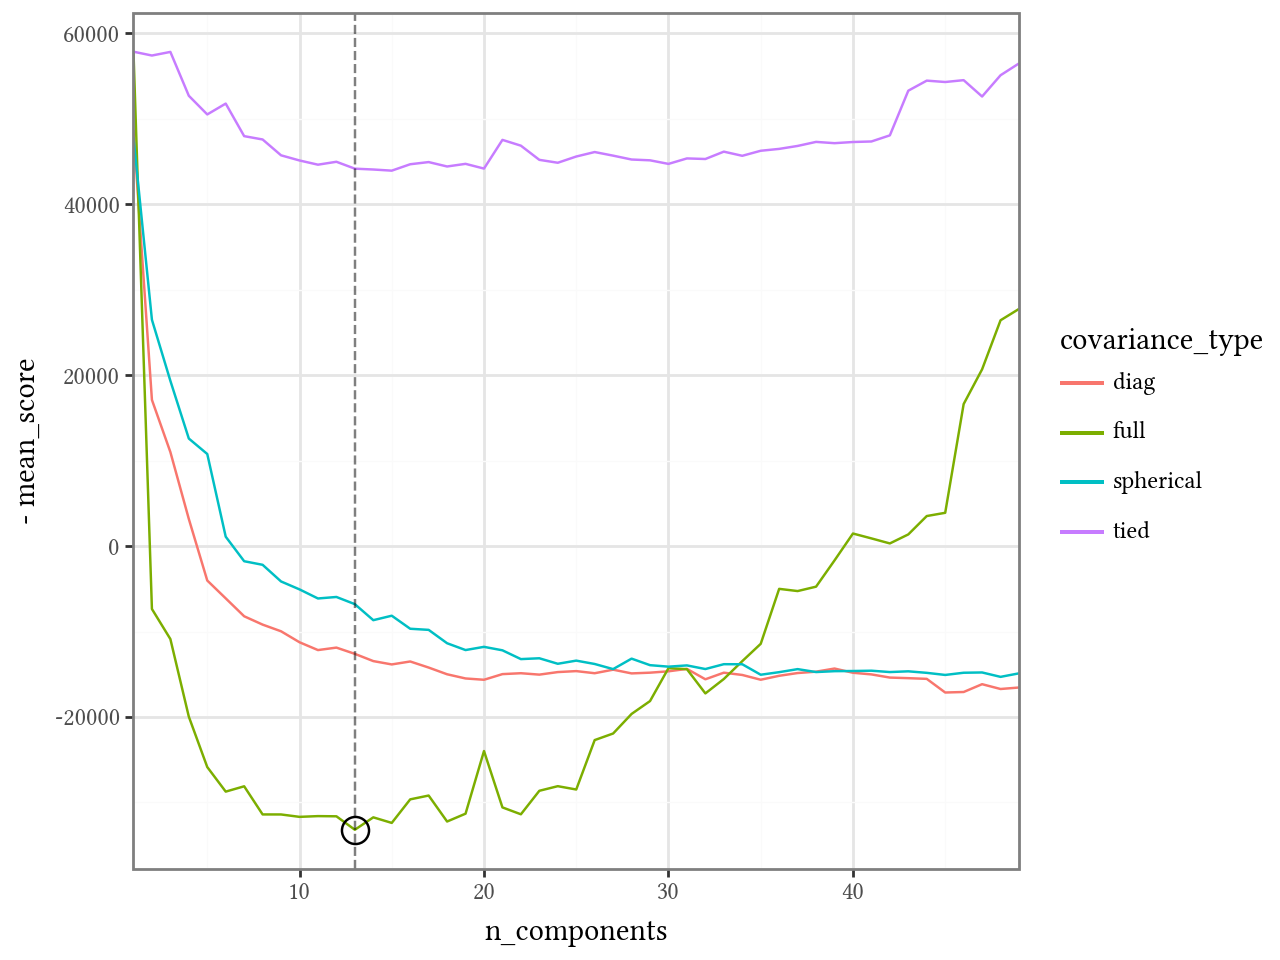

Saved file to outputs/gmm_clustering/plot_cv.png.


In [ ]:
# Set up models
def gmm_neg_bic(estimator: GaussianMixture, data: np.typing.NDArray | pd.DataFrame):
    return -estimator.bic(data)


param_grid = [
    {"n_components": range(1, 50), "covariance_type": ["spherical"]},
    {"n_components": range(1, 50), "covariance_type": ["tied"]},
    {"n_components": range(1, 50), "covariance_type": ["diag"]},
    {"n_components": range(1, 50), "covariance_type": ["full"]},
]
gmm_discov = GaussianMixture(random_state=np.random.RandomState(np.random.default_rng(2352).bit_generator))
grid_search_discov = GridSearchCV(gmm_discov, param_grid=param_grid, scoring=gmm_neg_bic, n_jobs=-1, refit=True)

gmm_valid = GaussianMixture(random_state=np.random.RandomState(np.random.default_rng(54645).bit_generator))

# Fit models
grid_search_discov.fit(data_discov_mfa)
print(f"Best parameters after cross-validation: {grid_search_discov.best_params_}")
plot_cv = make_plot_cv(grid_search_discov, group="covariance_type")
plot_cv.show()
save_plot(plot_cv, Path(outputs_folder, "plot_cv.png"), dpi=150)

gmm_valid.set_params(**grid_search_discov.best_params_)
gmm_valid.fit(data_valid_mfa)

model_discov = grid_search_discov.best_estimator_
model_valid = gmm_valid

In [ ]:
# Apply models to predict labels
labels_discov = predict_clustering_labels(model_discov, data_discov_mfa)
labels_valid = predict_clustering_labels(model_valid, data_valid_mfa)

# Apply models to predict probabilities
proba_discov = predict_clustering_proba(model_discov, data_discov_mfa)
proba_valid = predict_clustering_proba(model_valid, data_valid_mfa)

# Save predictions
proba_discov.assign(**{"label": labels_discov}).to_parquet(
    Path(outputs_folder, "cluster_pred_discov.parquet"), index=False
)
proba_valid.assign(**{"label": labels_valid}).to_parquet(
    Path(outputs_folder, "cluster_pred_valid.parquet"), index=False
)

### Display model information

Discovery:    13 clusters, 0.00% outliers
Percentage in clusters: {'0': 3.5993208828522922, '1': 38.17770232031692, '2': 0.7470288624787775, '3': 0.21505376344086022, '4': 3.1692133559705717, '5': 20.37351443123939, '6': 0.011318619128466328, '7': 2.252405206564799, '8': 17.917374080362194, '9': 0.20373514431239387, '10': 8.307866440294283, '11': 5.014148273910583, '12': 0.011318619128466328}
Validation:   13 clusters, 0.00% outliers
Percentage in clusters: {'0': 10.002328830926874, '1': 27.852817885421516, '2': 3.295295761527713, '3': 0.011644154634373545, '4': 19.003260363297624, '5': 10.18863530507685, '6': 5.55426176059618, '7': 2.5500698649278064, '8': 2.1891010712622263, '9': 18.58407079646018, '10': 0.7452258965999069, '11': 0.011644154634373545, '12': 0.011644154634373545}


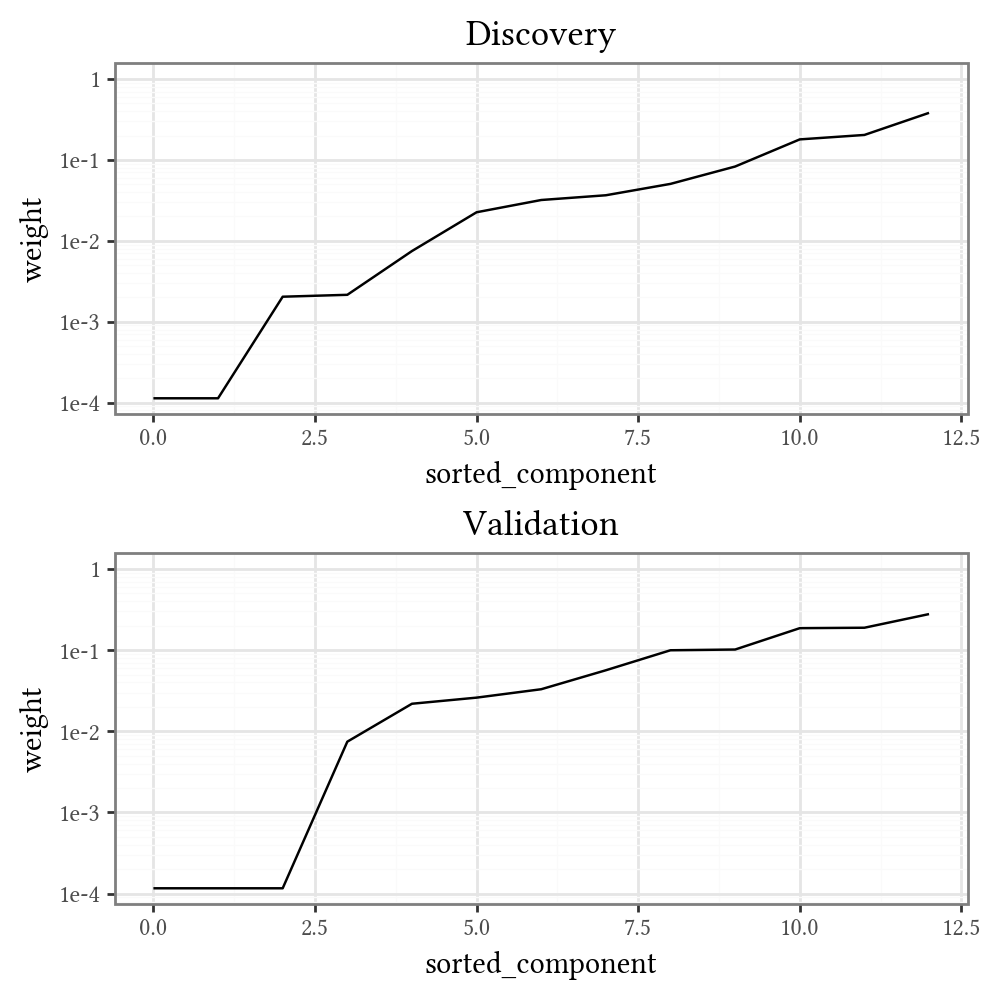

Saved file to outputs/gmm_clustering/plot_all_weights.png.


In [ ]:
# Print information about clusterings
print("Discovery:    ", end="")
print_clustering_info(labels_discov)
print("Validation:   ", end="")
print_clustering_info(labels_valid)

# Plot mixture weights
plot_discov_weights = make_plot_mixture_weights(model_discov)
plot_valid_weights = make_plot_mixture_weights(model_valid)

# save_plot(plot_discov_weights, Path(outputs_folder, "plot_discov_weights.png"), dpi=150)
# save_plot(plot_valid_weights, Path(outputs_folder, "plot_valid_weights.png"), dpi=150)

# Combine the two plots
plot_discov_weights += p9.labs(title="Discovery")
plot_valid_weights += p9.labs(title="Validation")
plot_all_weights = (plot_discov_weights / plot_valid_weights) & p9.theme(figure_size=(5, 5))

plot_all_weights.show()

save_plot(plot_all_weights, Path(outputs_folder, "plot_all_weights.png"), dpi=150)

### Get cluster summaries

In [ ]:
treat_cat_as_continuous = data_discov_full.meta.loc[lambda x: x["type"].isin(["binary", "ordinal"]), "name"]
data_discov_cont = turn_cats_to_continuous(data_discov_full.data, treat_cat_as_continuous).select_dtypes(
    exclude="category"
)
data_valid_cont = turn_cats_to_continuous(data_valid_full.data, treat_cat_as_continuous).select_dtypes(
    exclude="category"
)

In [3]:
# Interpretation of continuous, binary, and ordinal variables
cluster_discov_summaries = cluster_summaries(data_discov_cont, labels_discov, agg_func=["mean", "std"])  # "min", "max"
cluster_discov_summaries

cluster_discov_summaries = cluster_summaries(
    data_discov_cont,
    labels_discov,
    agg_func=["mean", "std"]
)

overall_mean = data_discov_cont.mean()
overall_std = data_discov_cont.std()

cluster_profiles = (
    cluster_discov_summaries.xs("mean", level=1, axis=1)
    - overall_mean
) / overall_std

cluster_profiles

NameError: name 'cluster_summaries' is not defined

In [ ]:
# Interpretation of continuous, binary, and ordinal variables
cluster_valid_summaries = cluster_summaries(data_valid_cont, labels_valid, agg_func=["mean", "std"])  # "min", "max"
cluster_valid_summaries

zeit         wichtn                 ges                alter  \
        mean  std      mean       std      mean       std       mean   
cluster                                                                
0        1.0  0.0  0.975818  0.859240  0.374854  0.484367  38.332945   
1        1.0  0.0  0.921021  0.706624  0.676003  0.468097  39.012542   
2        1.0  0.0  1.072730  1.064388  0.512367  0.500732  32.777385   
3        1.0  NaN  2.793923       NaN  0.000000       NaN  52.000000   
4        1.0  0.0  0.968607  0.779518  0.491422  0.500080  42.340686   
5        1.0  0.0  1.039034  0.982465  0.572571  0.494988  36.232000   
6        1.0  0.0  1.085604  0.938588  0.505241  0.500497  41.232704   
7        1.0  0.0  0.822946  0.677561  0.392694  0.489468  28.639269   
8        1.0  0.0  1.341377  1.233235  0.558511  0.497891  38.968085   
9        1.0  0.0  1.093366  0.933570  0.632832  0.482184  41.172306   
10       1.0  0.0  0.869454  0.731646  0.468750  0.502967  34.937500   
11       1.0  NaN  3.920717       NaN  0.000000       NaN  35.000000   
12       1.0  NaN  1.446211       NaN  0.000000       NaN  27.000000   

                        altq            ...  schm_kat            schl_kat  \
               std      mean       std  ...      mean       std      mean   
cluster                                 ...                                 
0        14.836513  3.086147  1.891468  ...  0.125728  0.342113  0.000000   
1        13.242291  3.247910  1.662184  ...  1.019231  0.572299  0.000000   
2        12.249037  2.416961  1.689348  ...  0.674912  0.753460  0.017668   
3              NaN  5.000000       NaN  ...  3.000000       NaN  0.000000   
4        14.353780  3.607843  1.757007  ...  0.000000  0.000000  0.000000   
5        13.886591  2.856000  1.839640  ...  0.000000  0.000000  0.000000   
6        15.962480  3.385744  2.050324  ...  1.628931  1.252997  0.368973   
7         8.673090  1.945205  1.360219  ...  0.716895  0.796919  0.100457   
8        14.398419  3.138298  1.859222  ...  1.425532  0.947717  0.531915   
9        14.089940  3.481203  1.744932  ...  1.023183  0.741997  0.164787   
10       14.027043  2.718750  1.794779  ...  1.171875  0.807793  0.312500   
11             NaN  3.000000       NaN  ...  1.000000       NaN  2.000000   
12             NaN  2.000000       NaN  ...  0.000000       NaN  0.000000   

                    ber_kat            depr_kat            neur_kat            
              std      mean       std      mean       std      mean       std  
cluster                                                                        
0        0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  
1        0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  
2        0.131974  0.000000  0.000000  0.049470  0.343673  0.000000  0.000000  
3             NaN  1.000000       NaN  0.000000       NaN  0.000000       NaN  
4        0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  
5        0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  
6        0.875748  0.350105  0.858145  0.505241  1.095480  0.119497  0.587311  
7        0.458307  0.063927  0.325555  0.146119  0.640113  0.018265  0.213393  
8        0.903968  0.574468  0.953343  0.792553  1.289425  0.367021  0.888656  
9        0.533317  0.000000  0.000000  0.400376  1.014985  0.065789  0.439501  
10       0.709907  0.218750  0.603396  0.421875  1.020499  0.218750  0.744690  
11            NaN  2.000000       NaN  3.000000       NaN  0.000000       NaN  
12            NaN  0.000000       NaN  0.000000       NaN  0.000000       NaN  

[13 rows x 214 columns]

### Compare clusterings
We are dealing with _inferential clustering_, because we are clustering individuals and not variables.\
Method-based validation: The same clustering method is applied to the validation data, and the results are compared between clusterings.\
Result-based validation: The trained cluster algorithm is applied to the validation data, and the results are compared between datasets.\
Cluster stability: The results from the trained and transferred clusterings from the method- and result-based validation steps are compared.

In [ ]:
# Compare clusterings
print_cluster_statistics(
    cluster_labels_list=[labels_discov, labels_valid],
    datas=[data_discov_mfa, data_valid_mfa],
    labels=["discovery", "validation"],
)

Comparison between ['discovery', 'validation']:

Discovery:   13 clusters, 0.00% outliers
Percentage in clusters: {'1': 38.17770232031692, '5': 20.37351443123939, '8': 17.917374080362194, '10': 8.307866440294283, '11': 5.014148273910583, '0': 3.5993208828522922, '4': 3.1692133559705717, '7': 2.252405206564799, '2': 0.7470288624787775, '3': 0.21505376344086022, '9': 0.20373514431239387, '6': 0.011318619128466328, '12': 0.011318619128466328}
Validation:  13 clusters, 0.00% outliers
Percentage in clusters: {'1': 27.852817885421516, '4': 19.003260363297624, '9': 18.58407079646018, '5': 10.18863530507685, '0': 10.002328830926874, '6': 5.55426176059618, '2': 3.295295761527713, '7': 2.5500698649278064, '8': 2.1891010712622263, '10': 0.7452258965999069, '3': 0.011644154634373545, '11': 0.011644154634373545, '12': 0.011644154634373545}

Davies‒Bouldin index discovery:   1.604978371413265
Davies‒Bouldin index validation:  1.9748832582928688

Caliński–Harabasz index discovery:   1005.629780579559